# Laboratorio: Captura y Análisis de Temperaturas en la Provincia de Elqui (OpenWeather + CEAZA)

**Propósito.** Implementar un flujo reproducible para:  
1) **extraer** las ciudades/lugares de la **Provincia de Elqui** desde CEAZA (scraping con *BeautifulSoup*),  
2) **recuperar** datos **históricos horarios** (o agregados diarios) de **OpenWeather** para **enero–agosto**,  
3) **limpiar, analizar y visualizar** las temperaturas para comparar ciudades y responder preguntas clave.

---

## Contexto y problema
La Provincia de Elqui (Región de Coquimbo, Chile) presenta variaciones térmicas entre costa, valle y cordillera. Se requiere capturar y estandarizar temperaturas de múltiples ciudades para compararlas de forma objetiva a lo largo de varios meses.

## Objetivo general
Construir un **pipeline reproducible** que tome ciudades desde CEAZA, obtenga temperaturas históricas (enero–agosto) desde OpenWeather y produzca análisis comparativos y visualizaciones.

## Objetivos específicos
- Extraer con **BeautifulSoup** los **nombres de ciudades/lugares** de la Provincia de Elqui (según CEAZA).
- Obtener **temperaturas horarias** (°C) o **agregados diarios** (min/mean/max) desde OpenWeather para enero–agosto.
- Limpiar y unificar: formatos de fecha, °C, valores faltantes, duplicados y outliers.
- Visualizar distribuciones por ciudad, comparar promedios por **mes y ciudad**, y series **día a día**.
- Responder: **¿Cuál es la ciudad más fría? ¿La más cálida?** Reportar **media, máxima y mínima** por ciudad y comparar **mes a mes** y **día a día**.

## Metodología (CRISP–DM)
- **Comprensión del negocio:** comparar climas locales (docencia, turismo, gestión territorial).
- **Comprensión de los datos:** ciudades/lugares (CEAZA); temperaturas (OpenWeather).
- **Preparación de datos:** scraping/requests; normalización a °C; conversión de timestamps; manejo de faltantes/outliers.
- **Modelado (exploratorio):** agregaciones (día/mes), resúmenes (mean/min/max), comparativas por ciudad.
- **Evaluación:** métricas descriptivas y respuestas a preguntas (fría/cálida, distribuciones).
- **Despliegue:** notebook reproducible y CSVs intermedios.

## 1) Instalación de librerias necesarias

In [1]:
!pip -q install beautifulsoup4 requests pandas matplotlib lxml

## 2) Importaciones y configuración

In [2]:
#@title Importaciones y parámetros generales
import os, re, time, json, math, calendar
from datetime import datetime, timedelta, timezone, date
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt

# Configuración principal
API_KEY = os.environ.get("OPENWEATHER_API_KEY", "")  # pega tu clave aquí o en una variable de entorno  #@param {type:"string"}
YEAR = 2025   #@param {type:"integer"}
MONTHS = list(range(1, 9))  # enero..agosto
METHOD = "history"  #@param ["history", "day_summary"] {allow-input: true}
MAX_CITIES = 12  #@param {type:"integer"}

# Parámetros auxiliares
UNITS = "metric"  # °C
SLEEP = 0.4       # respeto de límites de tasa (ajusta según plan)
TZ_LABEL = "-03:00"  # para day_summary (Chile)
OUTPUT_CSV = f"/content/elqui_openweather_{METHOD}_{YEAR}_jan_aug.csv"

assert API_KEY, "Por favor, pega tu API key de OpenWeather en la caja API_KEY y vuelve a ejecutar esta celda."

## 3) Extraer ciudades/lugares de CEAZA (Provincia de Elqui)

In [5]:
#@title Scraping de CEAZA (Provincia de Elqui)

CEAZA_URL = "https://www.ceazamet.cl/pronostico/"

resp = requests.get(CEAZA_URL, timeout=30)
resp.raise_for_status()
html = resp.text

soup = BeautifulSoup(html, "lxml")
text = soup.get_text(" ", strip=True)

# Heurística: buscar patrones con 'provincia=Elqui' y x=<lon>&y=<lat>
pat = re.compile(
    r"([A-Za-zÁÉÍÓÚÑñüÜ\-\(\)\/\s]+?)\s*x=(-?\d+\.\d+)&y=(-?\d+\.\d+)&provincia=Elqui",
    re.UNICODE
)

matches = pat.findall(text)
lugares = []
seen = set()

# Lista de palabras comunes del estado del clima que suelen aparecer pegadas al nombre
clima_words = [
    "Nublado", "Despejado", "Cubierto", "Parcial", "Parcialmente",
    "Chubascos", "Lluvia", "Nevado", "Nevada", "C", "car", "Soleado"
]

def limpiar_nombre(nombre):
    """Elimina palabras de clima y limpia espacios."""
    for palabra in clima_words:
        nombre = re.sub(rf"\b{palabra}\b", "", nombre, flags=re.IGNORECASE)
    return re.sub(r"\s+", " ", nombre).strip(" :\n\t")

for name, lon, lat in matches:
    place = limpiar_nombre(name)
    key = (place, float(lat), float(lon))
    if place and key not in seen:
        lugares.append({"place": place, "lat": float(lat), "lon": float(lon)})
        seen.add(key)

lugares_df = pd.DataFrame(lugares).drop_duplicates(subset=["place"]).reset_index(drop=True)

# Fallback si no se pudo extraer nada
if lugares_df.empty:
    fallback_places = ["La Serena", "Coquimbo", "Andacollo", "Vicuña", "Paihuano", "La Higuera"]
    lugares_df = pd.DataFrame({"place": fallback_places})
    print("No se pudo extraer automáticamente desde CEAZA; usando lista de fallback:", fallback_places)

lugares_df = lugares_df.head(MAX_CITIES)
lugares_df


ConnectTimeout: HTTPSConnectionPool(host='www.ceazamet.cl', port=443): Max retries exceeded with url: /pronostico/ (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x78bfe0795b50>, 'Connection to www.ceazamet.cl timed out. (connect timeout=30)'))

## 4) Geocodificar con OpenWeather (si faltan coordenadas)

In [ ]:
#@title Completar coordenadas faltantes con Geocoding API de OpenWeather
def geocode_city(name, country="CL"):
    url = "https://api.openweathermap.org/geo/1.0/direct"
    r = requests.get(url, params={"q": f"{name},{country}", "limit": 1, "appid": API_KEY}, timeout=30)
    r.raise_for_status()
    js = r.json()
    if js:
        return js[0]["lat"], js[0]["lon"]
    return None, None

if "lat" not in lugares_df.columns or "lon" not in lugares_df.columns:
    lugares_df["lat"] = None
    lugares_df["lon"] = None

for i, row in lugares_df.iterrows():
    if pd.isna(row.get("lat")) or pd.isna(row.get("lon")):
        lat, lon = geocode_city(row["place"])
        lugares_df.loc[i, "lat"] = lat
        lugares_df.loc[i, "lon"] = lon
        time.sleep(0.2)

lugares_df = lugares_df.dropna(subset=["lat","lon"]).reset_index(drop=True)
lugares_df

## 5) Funciones de captura (History API / Day Summary)

In [ ]:
#@title Utilidades de tiempo y llamadas a la API
def to_unix(dt):
    return int(dt.replace(tzinfo=timezone.utc).timestamp())

def monthly_windows(year, month, window_days=7):
    start = datetime(year, month, 1)
    last_day = calendar.monthrange(year, month)[1]
    end = datetime(year, month, last_day, 23, 59, 59)
    cur = start
    while cur <= end:
        nxt = min(cur + timedelta(days=window_days) - timedelta(seconds=1), end)
        yield to_unix(cur), to_unix(nxt)
        cur = nxt + timedelta(seconds=1)

def fetch_history_city(lat, lon, start_ts, end_ts, api_key, units="metric"):
    url = "https://history.openweathermap.org/data/2.5/history/city"
    params = {"lat": lat, "lon": lon, "type": "hour", "start": start_ts, "end": end_ts,
              "units": units, "appid": api_key}
    r = requests.get(url, params=params, timeout=60)
    if r.status_code == 401:
        raise RuntimeError("401 - Suscripción o API key inválida para History API. Verifica tu plan.")
    r.raise_for_status()
    return r.json()

def fetch_day_summary(lat, lon, date_iso, api_key, units="metric", tz="-03:00"):
    url = "https://api.openweathermap.org/data/3.0/onecall/day_summary"
    params = {"lat": lat, "lon": lon, "date": date_iso, "units": units, "tz": tz, "appid": api_key}
    r = requests.get(url, params=params, timeout=30)
    if r.status_code == 401:
        raise RuntimeError("401 - Suscripción o API key inválida para One Call 3.0 'day_summary'. Verifica tu plan.")
    r.raise_for_status()
    return r.json()

## 6) Descarga de datos (enero–agosto)

In [ ]:
#@title Orquestación de captura por ciudad y mes
def collect_month_history(lat, lon, year, month, api_key):
    frames = []
    for s, e in monthly_windows(year, month, window_days=7):
        js = fetch_history_city(lat, lon, s, e, api_key, units=UNITS)
        tz_off = (js.get("city") or {}).get("timezone", 0)  # segundos
        rows = []
        for it in js.get("list", []):
            dt_utc = datetime.utcfromtimestamp(it["dt"]).replace(tzinfo=timezone.utc)
            dt_loc = dt_utc + timedelta(seconds=tz_off)
            rows.append({
                "dt_utc": dt_utc,
                "dt_local": dt_loc,
                "temp": it["main"]["temp"],
                "temp_min": it["main"].get("temp_min"),
                "temp_max": it["main"].get("temp_max"),
                "humidity": it["main"].get("humidity"),
                "lat": lat, "lon": lon
            })
        frames.append(pd.DataFrame(rows))
        time.sleep(SLEEP)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def daterange(d1, d2):
    cur = d1
    while cur <= d2:
        yield cur
        cur += timedelta(days=1)

def collect_month_day_summary(lat, lon, year, month, api_key):
    start = date(year, month, 1)
    end = date(year, month, calendar.monthrange(year, month)[1])
    rows = []
    for d in daterange(start, end):
        js = fetch_day_summary(lat, lon, d.isoformat(), api_key, units=UNITS, tz=TZ_LABEL)
        temp = js.get("temperature") or {}
        rows.append({
            "date": d.isoformat(),
            "temp": temp.get("mean"),
            "temp_min": temp.get("min"),
            "temp_max": temp.get("max"),
            "lat": lat, "lon": lon
        })
        time.sleep(SLEEP)
    df = pd.DataFrame(rows)
    if not df.empty:
        df["dt_local"] = pd.to_datetime(df["date"])
    return df

# Captura principal
all_frames = []
for _, row in lugares_df.iterrows():
    city = row["place"]
    lat, lon = float(row["lat"]), float(row["lon"])
    print(f"Descargando {city} ({lat}, {lon})...")
    for m in MONTHS:
        if METHOD == "history":
            dfm = collect_month_history(lat, lon, YEAR, m, API_KEY)
        else:
            dfm = collect_month_day_summary(lat, lon, YEAR, m, API_KEY)
        if dfm.empty:
            print(f"  - Mes {m:02d}: sin datos devueltos.")
            continue
        dfm["city"] = city
        dfm["year"] = YEAR
        dfm["month"] = m
        if "dt_local" not in dfm.columns and "date" in dfm.columns:
            dfm["dt_local"] = pd.to_datetime(dfm["date"])
        dfm["date"] = dfm["dt_local"].dt.date
        all_frames.append(dfm)

hist_df = pd.concat(all_frames, ignore_index=True) if all_frames else pd.DataFrame()
print(hist_df.shape)
hist_df.head()

## 7) Limpieza y generación de agregados

In [ ]:
#@title Limpieza básica y agregaciones diarias/mensuales
assert not hist_df.empty, "No hay datos descargados. Revisa tu API key, plan de suscripción y que las ciudades tengan coordenadas válidas."

# Dedupe y filtro de plausibilidad
hist_df = hist_df.drop_duplicates(subset=["city","dt_local"]).reset_index(drop=True)
if "temp" in hist_df.columns:
    hist_df = hist_df[(hist_df["temp"] > -30) & (hist_df["temp"] < 50)]

# Agregaciones
daily = (hist_df.groupby(["city","date"], as_index=False)
         .agg(temp_mean=("temp","mean"),
              temp_min=("temp","min"),
              temp_max=("temp","max")))

monthly = (hist_df.groupby(["city","year","month"], as_index=False)
           .agg(temp_mean=("temp","mean"),
                temp_min=("temp","min"),
                temp_max=("temp","max")))

# Guardar CSV consolidado
hist_df.to_csv(OUTPUT_CSV, index=False)
print("Guardado:", OUTPUT_CSV)
daily.head(), monthly.head()

## 8) Visualizaciones

<Figure size 640x480 with 0 Axes>

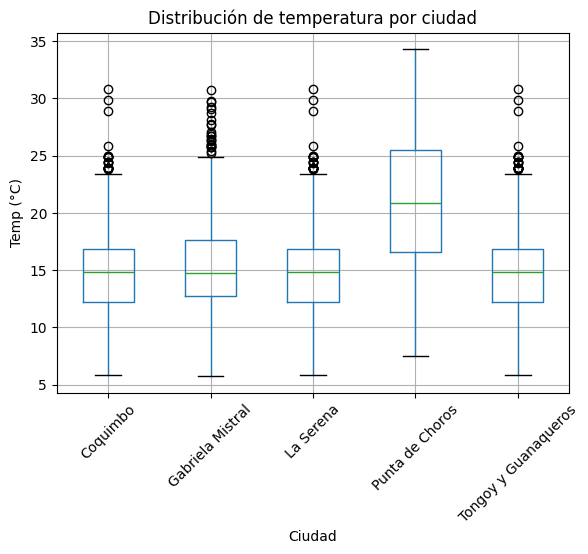

In [ ]:
#@title Distribución de temperatura por ciudad (boxplot)
plt.figure()
hist_df.boxplot(column="temp", by="city", rot=45)
plt.title("Distribución de temperatura por ciudad"); plt.suptitle("")
plt.xlabel("Ciudad"); plt.ylabel("Temp (°C)")
plt.show()

<Figure size 640x480 with 0 Axes>

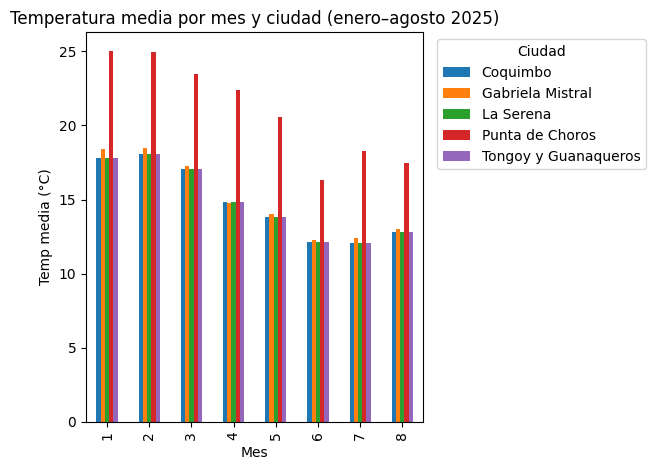

In [ ]:
#@title Temperatura media por mes y ciudad (barras)
pivot_m = monthly.pivot(index="month", columns="city", values="temp_mean").sort_index()
plt.figure()
pivot_m.plot(kind="bar")
plt.title(f"Temperatura media por mes y ciudad (enero–agosto {YEAR})")
plt.xlabel("Mes"); plt.ylabel("Temp media (°C)")
plt.legend(title="Ciudad", bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout(); plt.show()

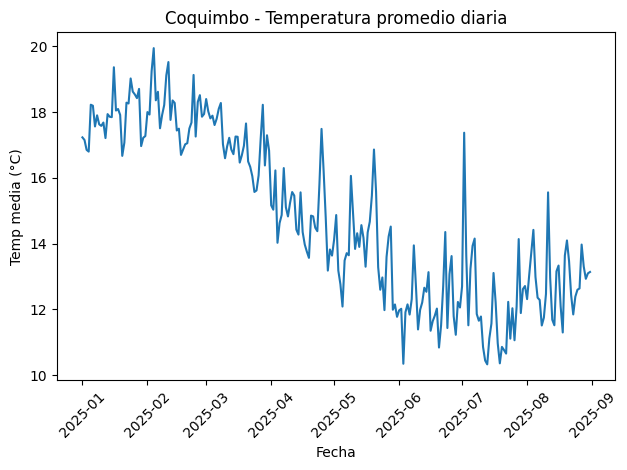

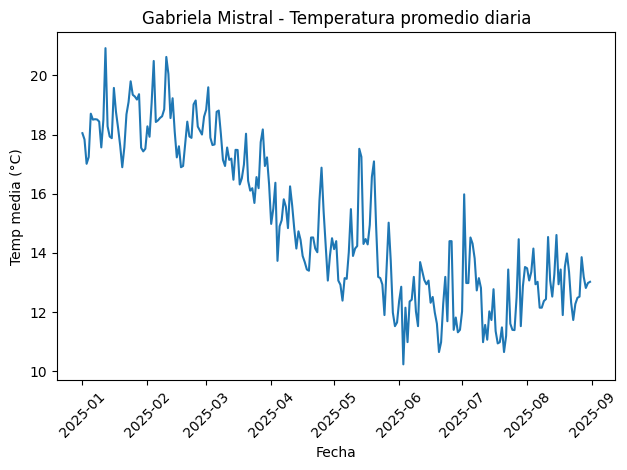

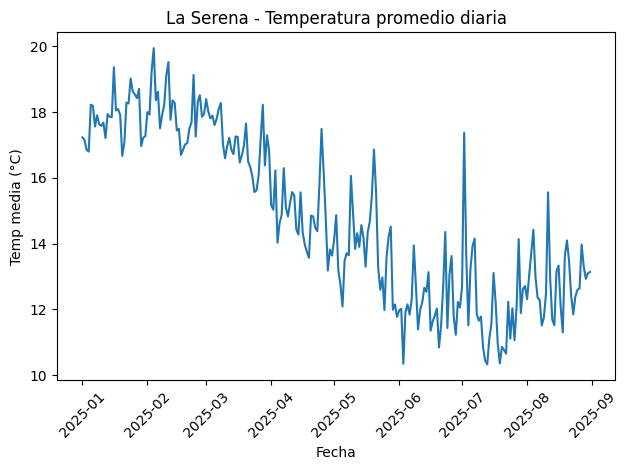

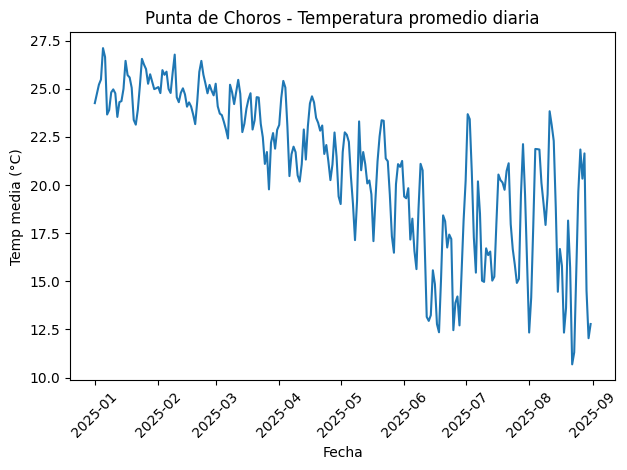

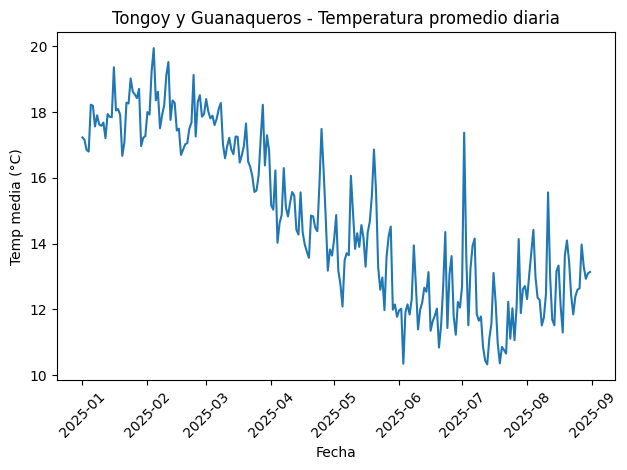

In [ ]:
#@title Serie diaria por ciudad (líneas) – hasta N ciudades
N = 6  #@param {type:"integer"}
for c in daily["city"].unique()[:N]:
    dfc = daily[daily["city"]==c].sort_values("date")
    plt.figure()
    plt.plot(dfc["date"], dfc["temp_mean"])
    plt.title(f"{c} - Temperatura promedio diaria")
    plt.xlabel("Fecha"); plt.ylabel("Temp media (°C)")
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 9) Análisis y respuestas

In [ ]:
#@title Ciudad más fría y más cálida (promedio enero–agosto)
city_stats = (hist_df.groupby("city", as_index=False)
              .agg(mean=("temp","mean"),
                   min=("temp","min"),
                   max=("temp","max")))

coldest = city_stats.sort_values("mean").iloc[0]
hottest = city_stats.sort_values("mean").iloc[-1]

print("Más fría (promedio):", coldest["city"], round(coldest["mean"],2), "°C")
print("Más cálida (promedio):", hottest["city"], round(hottest["mean"],2), "°C")

print("\nResumen global por ciudad (°C):")
display(city_stats.sort_values("mean"))

print("\nResumen por mes y ciudad (primeras filas):")
display(monthly.sort_values(["city","month"]).head(24))

Más fría (promedio): Coquimbo 14.81 °C
Más cálida (promedio): Punta de Choros 21.02 °C

Resumen global por ciudad (°C):


,city,mean,min,max
0,Coquimbo,14.813001,5.85,30.85
2,La Serena,14.813001,5.85,30.85
4,Tongoy y Guanaqueros,14.813001,5.85,30.85
1,Gabriela Mistral,15.042063,5.73,30.73
3,Punta de Choros,21.021715,7.50,34.31



Resumen por mes y ciudad (primeras filas):


,city,year,month,temp_mean,temp_min,temp_max
0,Coquimbo,2025,1,17.811491,13.32,24.99
1,Coquimbo,2025,2,18.058155,13.88,30.85
2,Coquimbo,2025,3,17.085903,11.85,29.85
3,Coquimbo,2025,4,14.864653,9.85,23.32
4,Coquimbo,2025,5,13.840161,7.85,22.85
5,Coquimbo,2025,6,12.163292,6.85,21.66
6,Coquimbo,2025,7,12.098925,5.85,22.85
7,Coquimbo,2025,8,12.841962,6.85,22.21
8,Gabriela Mistral,2025,1,18.382317,13.21,25.73
9,Gabriela Mistral,2025,2,18.467917,14.73,30.73
